# Coming from Brieflow

[Brieflow](https://github.com/cheeseman-lab/brieflow) runs an optical pooled screen from raw images to clustered genes as a Snakemake workflow.
The page below runs Brieflow's aggregate and cluster stages with mantispy, in the order Brieflow runs them, on a slice of Aconcagua, Brieflow's own reanalysis of a HeLa CRISPR screen.
Aconcagua's gene-level outputs are public, so the page compares the feature table, the bootstrap p-values and the closest genes with the ones Brieflow published.

The Brieflow code is cited at release 1.5.1, commit [`61457ae`](https://github.com/cheeseman-lab/brieflow/tree/61457ae1e50392bdf70852f4a87544fea4474e88), and every function name links to that commit.
The published outputs were made with Brieflow [1.4.10](https://github.com/cheeseman-lab/brieflow/tree/v1.4.10), as the screen's [metadata file](https://ops-explorer-public.s3.amazonaws.com/aconcagua/aconcagua/metadata/experimental_metadata.yaml) records.
The steps the page runs work the same way in both versions, apart from these differences in 1.4.10:

- Most of its settings have no defaults in its rules, so they come from the screen's configuration, although `feature_normalization` defaults to `"standard"` in both.
- Its default list of bootstrap features differs.
- Its feature table keeps a feature that some wells lack, where 1.5.1 drops it from every well.
- It picks the perturbation score's features once before the folds, where 1.5.1 picks them in each fold.

## The slice and the published outputs

{func}`~mantispy.ds.aconcagua_cells` holds the single cells of eight genes and a sample of the non-targeting control cells, with Brieflow's measurements under mantispy's feature names.
Brieflow runs every stage once per cell class ([`split_datasets`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/rules/aggregate.smk#L33)), so the page takes the interphase cells.
Run it again with `"Mitotic"` for the mitotic cells.
The published file is Brieflow's interphase gene table, with one row per gene and one per non-targeting guide, its features, the bootstrap p-values, and the PHATE and Leiden results.

In [1]:
import warnings

import anndata as ad
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
from scipy import stats

import mantispy as mt

# scanpy deprecated an argument mt.tl.cluster passes to it
warnings.filterwarnings("ignore", message="The argument key_added is deprecated", category=FutureWarning)

published = ad.read_h5ad(
    pooch.retrieve(
        "https://exampledata.scverse.org/mantispy/aconcagua/aconcagua_brieflow_interphase.h5ad",
        known_hash="sha256:f55756939edc8ddf108092d88c4efe248765b4db4ec39322d4b4a988e04af929",
        fname="aconcagua_brieflow_interphase.h5ad",
        path=mt.settings.cache_dir,
    )
)
cells = mt.ds.aconcagua_cells()
adata = cells[cells.obs["Metadata_Class"] == "Interphase"].copy()
GENES = sorted(set(adata.obs["Metadata_Gene"]) - {"nontargeting"})
print(f"published table: {published.n_obs} rows, {published.n_vars} features")

published table: 5299 rows, 76 features


mantispy keeps the cells in an {class}`~anndata.AnnData` object, with the cells as rows and the features as columns of `X`.
`obs` holds the per-cell metadata, `var` the per-feature metadata, `layers` other versions of `X`, `obsm` per-cell embeddings such as the PCA, and `uns` everything else.

The slice is a sample of the public cell table.
mantispy's [build script](https://github.com/scverse/mantispy/blob/a87ee5e379b8d38eb4161d4b8af1a2fc658fdc88/scripts/build_aconcagua.py) kept each cell with a probability set per gene or control guide, plate, well and class, which caps the cells of each gene and control guide in a well, and then kept a tenth of the control cells.
Both draws depend only on where a cell sits (its plate, well, tile and number, or its row in the file), never on its measurements.
The table below reads the build's probabilities and counts the cells at each stage.

In [2]:
keep = pd.read_parquet(
    pooch.retrieve(
        "https://raw.githubusercontent.com/scverse/mantispy/a87ee5e379b8d38eb4161d4b8af1a2fc658fdc88/scripts/data/aconcagua/keep_prob.parquet",
        known_hash="sha256:72c20141f2cab8353cb7b49d029d8da3907dbbabfde66bb5ab2e85197b1b1364",
        fname="aconcagua_keep_prob.parquet",
        path=mt.settings.cache_dir,
    )
)
keep = keep[keep["class"] == "Interphase"]
is_guide = ~keep["unit"].isin(published.obs_names)  # control rows are keyed by guide, gene rows by gene
keep["column"] = np.where(is_guide, "non-targeting", keep["unit"])
keep["expected"] = keep["n"] * keep["p_keep"] * np.where(is_guide, 0.1, 1.0)
brieflow_cells = (
    published.obs["n_cells"]
    .groupby(np.where(published.obs_names.str.startswith("nontargeting"), "non-targeting", published.obs_names))
    .sum()
)
slice_cells = adata.obs["Metadata_Gene"].astype(str).replace("nontargeting", "non-targeting").value_counts()
counts = pd.DataFrame(
    {
        "cells Brieflow aggregated": brieflow_cells,
        "cells in the public table": keep.groupby("column")["n"].sum(),
        "cells expected in the slice": keep.groupby("column")["expected"].sum(),
        "cells in the slice": slice_cells,
    }
).loc[[*GENES, "non-targeting"]]
share = (counts["cells in the slice"] / counts["cells Brieflow aggregated"]).round(2)
counts = counts.round().astype(int).astype(object)
counts["share in the slice"] = share
counts.T

,DTL,HAUS6,ITGAV,PSMB7,RRM1,SF3B3,SKA2,TLN1,non-targeting
cells Brieflow aggregated,2661,1717,4411,3079,4198,4896,773,4214,681919
cells in the public table,2670,1720,4431,3085,4216,4905,774,4220,682184
cells expected in the slice,1814,1543,1840,1832,1840,1840,765,1840,21249
cells in the slice,1781,1524,1823,1845,1821,1790,766,1881,22241
share in the slice,0.67,0.89,0.41,0.6,0.43,0.37,0.99,0.45,0.03


The public table holds the cells Brieflow aggregated, with counts that differ from Brieflow's by less than 1%, and the slice holds about the number of cells the draw expects.
SKA2 and HAUS6 have few enough cells per well that the cap keeps almost all of them, while the other genes and the controls lose more.
The comparisons below are limited by that sampling as well as by the methods.

## From your own Brieflow output

Brieflow writes one parquet file of cells per plate, well, cell class and channel combination after its filter step, with its own column names.
Rename the plate, well, gene and guide columns to mantispy's `Metadata_` names, drop the cells with no gene, mark the controls, and pass the remaining metadata columns from Brieflow's `metadata_cols_fp` file as `metadata_columns`.
The cell below does that for a table built from five cells of the slice, in Brieflow's column names.
With your own files, start from `pd.concat(pd.read_parquet(path) for path in paths)`.

In [3]:
FEATURE_NAMES = {"nucleus_DAPI_mean": "Nuclei_Intensity_MeanIntensity_DAPI", "cell_area": "Cells_AreaShape_Area"}
table = pd.DataFrame(
    {
        "plate": cells.obs["Metadata_Plate"].astype(int).to_numpy()[:5],
        "well": cells.obs["Metadata_Well"].astype(str).to_numpy()[:5],
        "tile": cells.obs["Metadata_Site"].to_numpy()[:5],
        "gene_symbol_0": cells.obs["Metadata_Gene"].astype(str).to_numpy()[:5],
        "cell_barcode_0": cells.obs["Metadata_sgRNA"].astype(str).to_numpy()[:5],
        **{name: cells[:5, ours].X.ravel() for name, ours in FEATURE_NAMES.items()},
    }
)

renamed = table.rename(
    columns={
        "plate": "Metadata_Plate",
        "well": "Metadata_Well",
        "gene_symbol_0": "Metadata_Gene",  # Brieflow's perturbation_name_col
        "cell_barcode_0": "Metadata_sgRNA",  # Brieflow's perturbation_id_col
    }
)
renamed = renamed[renamed["Metadata_Gene"].notna()]
renamed["Metadata_Control_Type"] = np.where(
    renamed["Metadata_Gene"].str.startswith("nontargeting"), "negcon", "treatment"
)
own = mt.io.from_dataframe(renamed, metadata_columns=["tile"], resolution="object")
own.var[["feature_kind"]]

,feature_kind
nucleus_DAPI_mean,embedding
cell_area,embedding


Brieflow's feature names don't follow CellProfiler's grammar, so {func}`~mantispy.io.from_dataframe` keeps them as features with `feature_kind="embedding"`.
Functions that pick features by name then can't see what each one measures, which is why `mt.ds.aconcagua_cells` renames them, and the [build script](https://github.com/scverse/mantispy/blob/a87ee5e379b8d38eb4161d4b8af1a2fc658fdc88/scripts/build_aconcagua.py) holds the full mapping.

## Label the cells

Brieflow's [`perturbation_filter`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/filter.py#L159) drops cells with no gene, and [`prepare_alignment_data`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/align.py#L17) renames each non-targeting cell after its guide, as `nontargeting_<barcode>`.
Every non-targeting guide is then a row of its own in the gene table and in the clustering, where the controls would otherwise collapse into one row.
`Metadata_Label` below holds that name, and `Metadata_Batch` the plate and well, which is Brieflow's batch.

In [4]:
adata = adata[adata.obs["Metadata_Gene"].notna()].copy()
is_control = (adata.obs["Metadata_Control_Type"] == "negcon").to_numpy()
adata.obs["Metadata_Label"] = np.where(
    is_control, "nontargeting_" + adata.obs["Metadata_sgRNA"].astype(str), adata.obs["Metadata_Gene"].astype(str)
)
adata.obs["Metadata_Batch"] = adata.obs["Metadata_Plate"].astype(str) + "_" + adata.obs["Metadata_Well"].astype(str)
print(
    f"{adata.n_obs} cells, {adata.obs['Metadata_Label'].nunique()} labels, {adata.obs['Metadata_Batch'].nunique()} wells"
)

35472 cells, 258 labels, 46 wells


## Filter

Brieflow's [`filter`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/rules/aggregate.smk#L61) rule runs once per plate, well and cell class.
[`missing_values_filter`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/filter.py#L188) drops the features missing in at least 10% of a well's cells (`drop_cols_threshold`), then the cells missing at least 1% of the features (`drop_rows_threshold`), and fills what is left with a KNN imputer of five neighbours.
In 1.5.1, a feature dropped in any well is lost from the whole screen when the wells are pooled.
[`intensity_filter`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/filter.py#L300) then fits a local outlier factor on the mean intensity of each channel in each object and drops the most outlying 1% of each well's cells.

The public table holds the cells Brieflow kept after this filter, so filtering them again would move the slice away from Brieflow's cells.
The cell below runs the filter on a copy, to show the calls and what they would drop, and the rest of the page keeps every cell.

In [5]:
filtered = adata.copy()
batch = filtered.obs["Metadata_Batch"].to_numpy()
print(f"missing values: {int(np.isnan(filtered.X).sum())}")

missing = pd.DataFrame(np.isnan(filtered.X), columns=filtered.var_names).groupby(batch).mean()
filtered = filtered[:, ~(missing >= 0.1).any().to_numpy()].copy()
filtered = filtered[np.isnan(filtered.X).mean(axis=1) < 0.01].copy()
mt.pp.impute(filtered, method="knn", n_neighbors=5, by="Metadata_Batch")

channels = ["DAPI", "TUBULIN", "GH2AX", "PHALLOIDIN"]  # Brieflow's phenotype.channel_names
filtered.var["intensity_mean"] = filtered.var_names.str.endswith(tuple(f"_MeanIntensity_{c}" for c in channels))
mt.pp.outliers(filtered, method="lof", contamination=0.01, key="intensity_mean", by="Metadata_Batch")
flagged = filtered.obs.groupby("Metadata_Gene", observed=True)["qc_outlier"].mean()
del filtered
flagged.rename("share of cells a second filter would drop").to_frame().T.round(3)

missing values: 0


Metadata_Gene,DTL,HAUS6,ITGAV,PSMB7,RRM1,SF3B3,SKA2,TLN1,nontargeting
share of cells a second filter would drop,0.018,0.007,0.013,0.011,0.046,0.022,0.004,0.018,0.006


The slice has no missing values, so the first three filter lines change nothing.
The outlier filter would still drop cells, because it always drops the most outlying 1% of each well.
It would drop more of some genes than of the controls.
A knockout that changes a stain's intensity moves its cells to the edge of the intensity distribution, so read these shares before trusting a strong intensity phenotype on your own screen, or pass a smaller `contamination`.

Where cells are missing values, {func}`~mantispy.pp.impute` differs from Brieflow in how it measures the distance between cells.
It uses every feature, where Brieflow uses only the features with missing values and adds a random sample of cells that are complete in those as donors.

## Feature table

Brieflow's [`generate_feature_table`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/scripts/aggregate/generate_feature_table.py) centres and scales every feature on the non-targeting cells of each plate and well ([`centerscale_on_controls`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/align.py#L266)), takes the median of each guide's cells, and then the median of each gene's guide medians.
Its `feature_normalization` setting picks the scaling, either `"standard"` for the mean and standard deviation, the [default](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/rules/aggregate.smk#L113), or `"mad"` for the median and the median absolute deviation (MAD), which is {func}`~mantispy.pp.normalize` with `method="mad_robustize"`.
The cell below builds the table both ways.

In [6]:
by = ["Metadata_Plate", "Metadata_Well"]
mt.pp.normalize(adata, method="standardize", by=by, reference="negcon", key_added="controls_standard")
mt.pp.normalize(adata, method="mad_robustize", by=by, reference="negcon", key_added="controls_mad")


def feature_table(layer):
    """Brieflow's gene table: the median of each guide's cells, then the median of each label's guides."""
    guides = mt.tl.aggregate(adata, by=["Metadata_Label", "Metadata_sgRNA"], func="median", min_cells=1, layer=layer)
    table = mt.tl.aggregate(guides, by=["Metadata_Label"], func="median", min_cells=1)
    table.obs_names = table.obs["Metadata_Label"].astype(str).to_numpy()
    return table


tables = {"standard": feature_table("controls_standard"), "mad": feature_table("controls_mad")}
print(
    f"{tables['mad'].n_obs} rows, all in the published table: {tables['mad'].obs_names.isin(published.obs_names).all()}"
)

WARNING  normalize: 34 of 1483 features have no reference spread in some ['Metadata_Plate', 'Metadata_Well'] group 
         and are NaN there

WARNING  normalize: 62 of 1483 features have no reference spread in some ['Metadata_Plate', 'Metadata_Well'] group 
         and are NaN there

258 rows, all in the published table: True


Both calls warn about features with no spread among some well's controls.
The MAD scaling flags more of them, since a feature whose value is shared by more than half of a well's controls has a MAD of zero.
Brieflow centres such a feature without dividing by its spread, while {func}`~mantispy.pp.normalize` sets it to missing in that well and flags it in `var`.
A well with no control cells at all is skipped by Brieflow and left unscaled, while {func}`~mantispy.pp.normalize` raises.

The published file keeps the features the screen's bootstrap tested.
They differ from what Brieflow's default feature list ([`get_feature_table_cols`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/cell_data_utils.py#L338)) selects, so the screen passed its own list in `bootstrap_features_fp`.
The function below renames them to mantispy's names, and the comparison correlates each gene's values with Brieflow's.

In [7]:
OBJECTS = {"nucleus": "Nuclei", "cell": "Cells"}
INTENSITY = {
    "integrated": "IntegratedIntensity",
    "mean": "MeanIntensity",
    "mean_edge": "MeanIntensityEdge",
    "std_edge": "StdIntensityEdge",
    "mass_displacement": "MassDisplacement",
}
SHAPE = {"area": "Area", "form_factor": "FormFactor", "solidity": "Solidity", "eccentricity": "Eccentricity"}


def mantispy_name(name):
    """The mantispy name of one of Brieflow's published features."""
    obj, rest = name.split("_", 1)
    obj = OBJECTS[obj]
    if rest in SHAPE:
        return f"{obj}_AreaShape_{SHAPE[rest]}"
    if rest.startswith("correlation_"):
        _, a, b = rest.split("_")
        return f"{obj}_Correlation_Correlation_{a}_{b}"
    channel, stat = rest.split("_", 1)
    if stat.startswith("mean_frac_"):
        return f"{obj}_RadialDistribution_MeanFrac_{channel}_{int(stat[-1]) + 1}of4"
    return f"{obj}_Intensity_{INTENSITY[stat]}_{channel}"


FEATURES = pd.Series(published.var_names.map(mantispy_name), index=published.var_names)
brieflow = pd.DataFrame(np.asarray(published.X), index=published.obs_names, columns=published.var_names)


def as_published(table):
    """A table's published features, under Brieflow's names."""
    return pd.DataFrame(np.asarray(table[:, FEATURES.to_numpy()].X), index=table.obs_names, columns=published.var_names)


rows = {}
for scaling, table in tables.items():
    ours = as_published(table).loc[GENES]
    rows[f"correlation, {scaling}"] = {gene: np.corrcoef(ours.loc[gene], brieflow.loc[gene])[0, 1] for gene in GENES}
    rows[f"slope, {scaling}"] = {gene: np.polyfit(brieflow.loc[gene], ours.loc[gene], 1)[0] for gene in GENES}
pd.DataFrame(rows).T.round(3)

,DTL,HAUS6,ITGAV,PSMB7,RRM1,SF3B3,SKA2,TLN1
"correlation, standard",0.920,0.111,0.929,0.904,0.963,0.833,0.171,0.924
"slope, standard",0.533,0.181,0.699,0.753,0.573,0.517,0.179,0.743
"correlation, mad",0.999,0.975,0.998,0.997,1.000,0.992,0.988,0.997
"slope, mad",1.012,0.972,1.000,0.977,0.989,0.952,1.015,1.053


With the median and MAD scaling, every gene's profile matches Brieflow's in shape and in size, with slopes close to one.
Aconcagua was therefore run with `feature_normalization: mad`.
With Brieflow's default scaling the values come out smaller, and for HAUS6 and SKA2 the correlation is lost.
Check the setting in your own configuration before comparing numbers.

The non-targeting rows agree less well, because each control guide in the slice keeps a few percent of its cells.

In [8]:
controls = [label for label in tables["mad"].obs_names if label.startswith("nontargeting")]
ours = as_published(tables["mad"]).loc[controls]
correlation = np.median([np.corrcoef(ours.loc[c], brieflow.loc[c])[0, 1] for c in controls])
print(f"median correlation over {len(controls)} control guides: {correlation:.3f}")
for layer in ["controls_standard", "controls_mad"]:
    flagged = adata.var.loc[FEATURES.to_numpy(), f"degenerate_scale_{layer}"]
    print(f"{layer}: {int(flagged.sum())} of the {len(FEATURES)} published features flagged")

median correlation over 250 control guides: 0.270
controls_standard: 0 of the 76 published features flagged
controls_mad: 0 of the 76 published features flagged


None of the published features is flagged.

## Feature bootstrap

Brieflow's [`run_gene_bootstrap`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/bootstrap.py#L428) tests each feature of each gene against medians resampled from the control guides' cells, on the feature table above, and [`apply_multiple_hypothesis_correction`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/bootstrap.py#L651) adds Benjamini-Hochberg q-values over every gene and feature.
It tests the features in `bootstrap_features_fp`, or without that file the default list ([`prepare_bootstrap_data`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/scripts/aggregate/prepare_bootstrap_data.py#L98)), so subset the object to the same features first.
{func}`~mantispy.tl.bootstrap_features` computes the null exactly, where Brieflow simulates it 100,000 times ([`num_sims`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/rules/aggregate.smk#L390)).
`method="median"` tests Brieflow's statistic, the median of a gene's guides' medians, and `median="midpoint"` takes the median of an even count, of cells or of guides, as the mean of the two middle ones, as Brieflow does.
The defaults instead combine a gene's guides' exact p-values by Stouffer's method, weighted by each guide's cells, and take the lower of the two middle cells, which makes the test far faster.

In [9]:
tested = adata[:, FEATURES.to_numpy()].copy()
mt.tl.bootstrap_features(
    tested,
    groupby="Metadata_Gene",
    replicate="Metadata_sgRNA",
    reference="negcon",
    control_scope="pooled",
    layer="controls_mad",
    method="median",
    median="midpoint",
)
boot = tested.uns["mantispy"]["bootstrap"]
brieflow_p = pd.DataFrame(published.layers["p_values"], index=published.obs_names, columns=published.var_names)
brieflow_name = dict(zip(FEATURES, FEATURES.index, strict=True))
boot["brieflow_pvalue"] = [
    brieflow_p.at[gene, brieflow_name[feature]] for gene, feature in zip(boot["group"], boot["feature"], strict=True)
]
print(f"Spearman correlation of the p-values: {stats.spearmanr(boot['pvalue'], boot['brieflow_pvalue'])[0]:.3f}")
print(
    f"p-values of zero: {int((boot['pvalue'] == 0).sum())} from mantispy, {int((boot['brieflow_pvalue'] == 0).sum())} from Brieflow"
)
ours_called, theirs_called = boot["pvalue"] < 0.05, boot["brieflow_pvalue"] < 0.05
pd.DataFrame(
    {
        "both": (ours_called & theirs_called).groupby(boot["group"]).sum(),
        "mantispy only": (ours_called & ~theirs_called).groupby(boot["group"]).sum(),
        "Brieflow only": (~ours_called & theirs_called).groupby(boot["group"]).sum(),
    }
).T

Spearman correlation of the p-values: 0.849
p-values of zero: 47 from mantispy, 370 from Brieflow


group,DTL,HAUS6,ITGAV,PSMB7,RRM1,SF3B3,SKA2,TLN1
both,60,4,59,57,61,48,18,59
mantispy only,0,0,0,0,0,0,0,0
Brieflow only,10,21,11,15,9,16,12,12


The table counts the features each method puts below p < 0.05 for each gene.
Brieflow's q-values correct over every gene of the screen and the slice's over eight, so the comparison uses p-values.
The counts are therefore not calls.
Every feature below 0.05 for mantispy is below 0.05 for Brieflow too, and for every gene Brieflow puts more features below it.
The bootstrap null draws from the control guides' cells, of which the slice keeps a few percent, and the slice alone can't tell how much of the difference that accounts for.

mantispy also differs on purpose in how it treats p-values at the edge of the null.
Brieflow's simulated p-value is zero whenever the observed median lies beyond all 100,000 null medians, on either side, and it raises a zero to `1 / num_sims` before the correction.
mantispy computes each p-value exactly, so it is zero only when the observed median lies beyond every median the null can produce.
mantispy keeps that zero.
Brieflow also counts a null median equal to the observed one as below it, where mantispy counts it as half.

## Align

Brieflow's [`align`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/scripts/aggregate/align.py) script scores perturbations, centres and scales every cell within its plate and well, reduces with PCA, and applies TVN and CORAL.
It starts again from the filtered cells, not from the feature table.

### Perturbation score

Brieflow skips this step by default ([`skip_perturbation_score: True`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/rules/aggregate.smk#L146)), and the published file has no AUCs to compare with.
When it runs, [`perturbation_score`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/perturbation_score.py#L27) fits a logistic regression per gene, on the 200 features with the largest ANOVA F statistic, against as many control cells as the gene has, and records each cell's out-of-fold probability and each gene's ROC AUC.
It needs 100 cells for the gene and its control sample together, so `min_cells=50`.
It uses ten folds once the two reach 200 cells ([`n_splits`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/perturbation_score.py#L195)), which every gene in the slice does.
Brieflow centres and scales each gene's sample on that sample's own control cells with the mean and standard deviation, whatever `feature_normalization` says, while mantispy reads the `controls_standard` layer, which is scaled on all of a well's controls.

`replicate=None` draws the folds over cells, as Brieflow does, and warns that mantispy's default is safer, which is expected here.
mantispy's default, `replicate="Metadata_sgRNA"`, keeps each guide's cells in one fold, so the model is always tested on a guide it was not trained on.
The cell drops the features that have no spread among some well's controls, which the model can't read, and runs both.

In [10]:
standard_flags = adata.var["degenerate_scale_controls_standard"].to_numpy()
print(f"dropping {int(standard_flags.sum())} features with no spread among some well's controls")
adata = adata[:, ~standard_flags].copy()
for replicate, key in [(None, "perturbation_score"), ("Metadata_sgRNA", "perturbation_score_by_guide")]:
    mt.tl.perturbation_score(
        adata,
        groupby="Metadata_Gene",
        reference="negcon",
        layer="controls_standard",
        replicate=replicate,
        n_features=200,
        n_folds=10,
        min_cells=50,
        key_added=key,
    )
scores = {
    "over cells": adata.uns["mantispy"]["perturbation_score"].set_index("group"),
    "over guides": adata.uns["mantispy"]["perturbation_score_by_guide"].set_index("group"),
}
summary = pd.DataFrame({f"AUC, folds {kind}": table["auc"] for kind, table in scores.items()}).T.round(3)
folds = pd.DataFrame({f"folds {kind}": table["n_folds"] for kind, table in scores.items()}).T
guides = adata.obs.groupby("Metadata_Gene", observed=True)["Metadata_sgRNA"].nunique().rename("guides").to_frame().T
pd.concat([summary.astype(object), folds.astype(object), guides[GENES].astype(object)])

dropping 34 features with no spread among some well's controls


<path>:5: UserWarning: replicate=None draws folds over cells, so the model can learn what one guide's cells share and score it as the group's phenotype. Pass replicate= the guide column, e.g. replicate='Metadata_sgRNA'.
  mt.tl.perturbation_score(


,DTL,HAUS6,ITGAV,PSMB7,RRM1,SF3B3,SKA2,TLN1
"AUC, folds over cells",0.812,0.618,0.863,0.844,0.85,0.706,0.597,0.857
"AUC, folds over guides",0.795,0.608,0.854,0.822,0.841,0.64,0.553,0.843
folds over cells,10,10,10,10,10,10,10,10
folds over guides,4,4,4,4,4,4,4,4
guides,4,4,4,4,4,4,4,4


The guide folds give lower AUCs, because a gene's AUC no longer gains from the model learning what one guide's cells look like.
They also cap the folds at the gene's number of guides.
A gene with too few cells gets no AUC, and Brieflow's AUC filter then drops it, since a missing AUC is not above any threshold.
Knockouts of essential genes lose cells, so the strongest phenotypes are the ones most at risk of that.

### PCA

Brieflow's [`centerscale_by_batch`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/align.py#L223) standardizes every cell within its plate and well, and [`align.py`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/scripts/aggregate/align.py#L94) fits `PCA(n_components=0.99)` on a random sample of at most 100,000 cells, which here is every cell, keeping the fewest components that explain 99% of the variance.
The cell drops any further feature with no spread in some well, fits the full PCA once to find that number, and then refits with it, so that `varm` and `uns` describe the components kept.

In [11]:
mt.pp.normalize(adata, method="standardize", by=by, reference=None)
degenerate = adata.var["degenerate_scale"] | adata.var["degenerate_scale_controls_standard"]
print(f"dropping {int(degenerate.sum())} more features with no spread in some well")
adata = adata[:, ~degenerate.to_numpy()].copy()

sc.pp.pca(adata, n_comps=adata.n_vars - 1, svd_solver="covariance_eigh")
n_comps = int(np.searchsorted(np.cumsum(adata.uns["pca"]["variance_ratio"]), 0.99, side="right")) + 1
sc.pp.pca(adata, n_comps=n_comps, svd_solver="covariance_eigh")

n_wells = adata.obs["Metadata_Batch"].nunique()
controls_per_well = adata.obs[is_control].groupby("Metadata_Batch", observed=True).size()
print(
    f"{n_comps} components; {controls_per_well.min()} to {controls_per_well.max()} control cells in each of {n_wells} wells"
)
print(f"Brieflow's control cells per well, on average: {brieflow_cells['non-targeting'] / n_wells:.0f}")

dropping 0 more features with no spread in some well


727 components; 393 to 534 control cells in each of 46 wells
Brieflow's control cells per well, on average: 14824


### TVN and CORAL

TVN (typical variation normalization) whitens the profiles so that the variation among control cells has the same size in every direction, and CORAL (correlation alignment) gives each well's controls the covariance of all the controls.
Brieflow's [`tvn_on_controls`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/align.py#L143) centres and scales the components on the controls, rotates them onto the principal components of the controls, centres and scales them again on each well's controls, and then aligns each well with CORAL.
`epsilon=0.5` is the shrinkage it adds to the diagonal of each covariance.

Brieflow skips CORAL for a well with fewer controls than components ([`align.py`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/align.py#L200)).
Every well of the slice has fewer, as printed above, so on this slice Brieflow would align no well.
On the full screen, Brieflow's control cells averaged over the slice's wells are many times the slice's components, as printed above.
{func}`~mantispy.pp.tvn` aligns every well instead, with a warning, so the cell reproduces Brieflow's result directly.
With every cell in one batch, {func}`~mantispy.pp.tvn` centres, scales and rotates on all the controls, and its CORAL step leaves the values unchanged, because it whitens and recolours with the same covariance.
Centring and scaling each well on its own controls then adds the step Brieflow still runs.
On a full screen, with more controls per well than components, call `mt.pp.tvn(adata, batch_key="Metadata_Batch", reference="negcon", use_rep="X_pca", epsilon=0.5)` instead.

In [12]:
adata.obs["Metadata_AllWells"] = "all"
mt.pp.tvn(adata, batch_key="Metadata_AllWells", reference="negcon", use_rep="X_pca", epsilon=0.5)
components = ad.AnnData(adata.obsm["X_tvn"], obs=adata.obs[[*by, "Metadata_Control_Type"]])
mt.pp.normalize(components, method="standardize", by=by, reference="negcon")
adata.obsm["X_tvn"] = components.X

## Aggregate

Brieflow's [`aggregate`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/aggregate/aggregate.py#L14) takes the median of the TVN components over all the cells of each gene, and of each non-targeting guide.
It can first drop the cells whose perturbation score is below `ps_probability_threshold`, keeping the cells with no score, and it doesn't by default.
It would keep the cells that look least like the controls.
The gene profiles would then sit further from the controls, and closer to other strongly scored genes, than all of the gene's cells do.
[`clean_aggregate`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/scripts/cluster/clean_aggregate.py) then keeps the rows with more than `min_cell_cutoffs[cell_class]` cells, a setting with no default.

In [13]:
ps_probability_threshold = None  # Brieflow's default
if ps_probability_threshold is not None:
    adata = adata[~(adata.obs["perturbation_score"] < ps_probability_threshold)].copy()
genes = mt.tl.aggregate(adata, by=["Metadata_Label"], func="median", min_cells=1, use_rep="X_tvn")
genes.obs_names = genes.obs["Metadata_Label"].astype(str).to_numpy()

min_cell_cutoff = 0  # set from min_cell_cutoffs[cell_class] in your Brieflow configuration
genes = genes[genes.obs["Metadata_CellCount"] > min_cell_cutoff].copy()
genes

AnnData object with n_obs × n_vars = 258 × 727
    obs: 'Metadata_Label', 'Metadata_CellCount', 'Metadata_SiteCount', 'Metadata_Gene', 'Metadata_Perturbation', 'Metadata_Perturbation_Type', 'Metadata_Control_Type', 'Metadata_Class', 'Metadata_Tier', 'Metadata_Control', 'Metadata_ObjectType', 'Metadata_AllWells'
    var: 'object', 'feature_group', 'feature', 'channel', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind'
    uns: 'mantispy'
    layers: None (.X)

`min_cells=1` turns off mantispy's own minimum of 10 cells, so the cut-off is applied once.

## Cluster

Brieflow's [`phate_leiden_clustering`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/scripts/cluster/phate_leiden_clustering.py#L28) script first applies [`filter_by_perturbation_auc`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/cluster/phate_leiden_clustering.py#L308), which is off by default ([`perturbation_auc_threshold`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/rules/cluster.smk#L42)).
It then embeds the rows with PHATE ([`run_phate`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/cluster/phate_leiden_clustering.py#L83), ten neighbours, cosine distance by [default](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/rules/cluster.smk#L35)) and clusters them with Leiden at each configured resolution.
The workflow doesn't filter genes on the bootstrap before clustering.
{func}`~mantispy.tl.phate` implements PHATE with the parameter names of `phate.PHATE`.
Its automatic choice of the number of diffusion steps `t` can land on a different value than phate's, so pass `t=` to match a given run.

In [14]:
perturbation_auc_threshold = None  # Brieflow's default
if perturbation_auc_threshold is not None:
    auc = adata.uns["mantispy"]["perturbation_score"].set_index("group")["auc"]
    control = genes.obs["Metadata_Control_Type"] == "negcon"
    genes = genes[control | (genes.obs["Metadata_Gene"].map(auc) > perturbation_auc_threshold)].copy()

mt.tl.phate(genes, knn=10, metric="cosine", use_rep=None, t=None, seed=42)  # pass t= to match a Brieflow run
mt.tl.cluster(genes, method="leiden", neighbors_key="phate", resolution=1.0)

Brieflow publishes the clusters of all its genes, and Leiden's clusters depend on every row in the graph, so the clusters of eight genes and the controls can't match them.
What carries over is which genes sit closest, so the cell below gives each gene's most similar other gene in the TVN profiles, with the cosine similarity, beside mantispy's cluster and the genes Brieflow put in the same cluster.

In [15]:
profiles = genes[GENES].X
unit = profiles / np.linalg.norm(profiles, axis=1, keepdims=True)
similarity = unit @ unit.T
np.fill_diagonal(similarity, -np.inf)
brieflow_cluster = published.obs.loc[GENES, "cluster_group_1"]
pd.DataFrame(
    {
        "nearest gene": np.array(GENES)[similarity.argmax(axis=1)],
        "cosine similarity": similarity.max(axis=1).round(2),
        "mantispy cluster": genes.obs.loc[GENES, "cluster"].to_numpy(),
        "same Brieflow cluster": [
            ", ".join(g for g in GENES if g != gene and brieflow_cluster[g] == brieflow_cluster[gene]) or "none"
            for gene in GENES
        ],
    },
    index=GENES,
)

,nearest gene,cosine similarity,mantispy cluster,same Brieflow cluster
DTL,RRM1,0.48,0,RRM1
HAUS6,SKA2,0.29,1,SKA2
ITGAV,TLN1,0.84,1,TLN1
PSMB7,DTL,0.44,0,none
RRM1,DTL,0.48,0,DTL
SF3B3,RRM1,0.29,0,none
SKA2,HAUS6,0.29,1,HAUS6
TLN1,ITGAV,0.84,1,ITGAV


Every gene that shares a Brieflow cluster with another of the eight has that gene as its nearest neighbour here, and mantispy's Leiden puts each of those pairs in one cluster.
With only two clusters for the eight genes, mantispy's Leiden also groups genes that Brieflow separates.
The similarities say how close each pair is. ITGAV and TLN1 are close, while HAUS6 and SKA2 are no closer than SF3B3 is to RRM1, which Brieflow puts in different clusters.

mantispy clusters on a different graph from Brieflow.
Brieflow runs Leiden on PHATE's diffusion operator, the affinity with each row normalized to sum to one, averaged with its transpose, and iterates Leiden until the partition stops changing ([`run_leiden_clustering`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/lib/cluster/phate_leiden_clustering.py#L127)).
{func}`~mantispy.tl.phate` stores the symmetric affinity before that normalization, in the layout {func}`scanpy.pp.neighbors` uses, so that scanpy's graph tools can read it.
{func}`~mantispy.tl.cluster` then runs {func}`scanpy.tl.leiden` on that graph.
The {doc}`PHATE and Leiden case study <../../case_studies/phate_leiden>` compares the clusters from that graph with Brieflow's published clusters on the full screen, across resolutions and seeds, and a pair of genes that shares a cluster across those is the one to read.
Brieflow's [`benchmark_clusters`](https://github.com/cheeseman-lab/brieflow/blob/61457ae1e50392bdf70852f4a87544fea4474e88/workflow/scripts/cluster/benchmark_clusters.py) scores the clusters against CORUM, KEGG and STRING, while {func}`~mantispy.metrics.known_relationships` scores the profiles against CORUM without a clustering.

## Reading the results

The bootstrap tests one feature at a time, so it doesn't say whether a gene differs from the controls as a whole.
{doc}`interpreting a screen <interpreting_a_screen>` and {doc}`hit calling methods <hit_calling_methods>` work through that question, including whether a gene's guides agree.
Every targeting guide cuts DNA and a non-targeting guide does not, so against non-targeting controls the cut alone can move gamma-H2AX and other DNA damage features.
A change in those features doesn't by itself show the effect of losing the gene.
Guides against genes the cells don't express also cut, and {doc}`hit calling methods <hit_calling_methods>` shows how passing them as the reference changes the calls.
A gene that shows little change in interphase may still act in mitosis, as HAUS6 and SKA2 may, since they work at the spindle and the kinetochore.
Check the mitotic cells before reading such a gene as having no phenotype.

## Speed and memory on the full screen

mantispy runs the steps above faster than Brieflow on a full screen, and with less memory for most of them.
We ran each step with Brieflow 1.5.1 and with mantispy on all 30.3 million interphase cells of Aconcagua, both on the same 32-thread node, and checked that their outputs agree.
The cell below holds the measured wall times and peak memory, copied from that benchmark.

filter to gene aggregation: Brieflow 2.14 h, mantispy 24.8 min


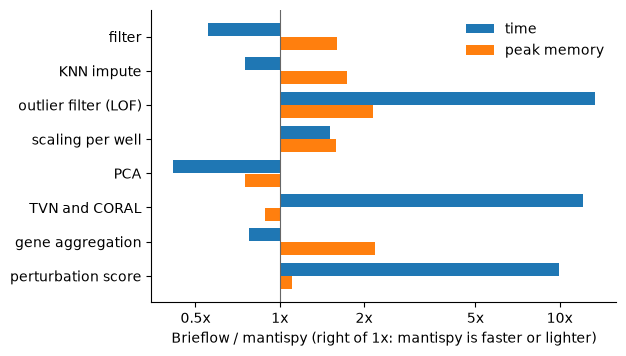

In [16]:
import matplotlib.pyplot as plt

# Wall time in seconds and peak memory in GB per step, measured on 2026-11-18 on all 30.3M interphase cells of
# Aconcagua: Brieflow 1.5.1 against mantispy at #348, each pair in one Slurm job on one 32-thread Xeon Gold 6142 node.
# The times include starting Python and reading and writing each step's files.
bench = pd.DataFrame(
    [
        ("filter", 143.2, 55.0, 257.8, 34.4),
        ("KNN impute", 108.9, 50.5, 145.0, 29.0),
        ("outlier filter (LOF)", 5038.2, 64.2, 375.6, 29.9),
        ("scaling per well", 297.7, 45.8, 197.3, 28.8),
        ("PCA", 52.5, 20.7, 126.8, 27.6),
        ("TVN and CORAL", 1894.0, 36.4, 156.8, 41.2),
        ("gene aggregation", 177.8, 71.4, 229.5, 32.6),
        ("perturbation score", 11229.4, 31.0, 1132.3, 28.0),
    ],
    columns=["step", "brieflow_s", "brieflow_gb", "mantispy_s", "mantispy_gb"],
).set_index("step")
main_chain = bench.drop("perturbation score").sum()
print(
    f"filter to gene aggregation: Brieflow {main_chain['brieflow_s'] / 3600:.2f} h, mantispy {main_chain['mantispy_s'] / 60:.1f} min"
)

ratios = {
    "time": bench["brieflow_s"] / bench["mantispy_s"],
    "peak memory": bench["brieflow_gb"] / bench["mantispy_gb"],
}
rows = np.arange(len(bench))[::-1]
fig, ax = plt.subplots(figsize=(6, 3.8))
for offset, (label, ratio) in zip([0.2, -0.2], ratios.items(), strict=True):
    ax.barh(rows + offset, ratio - 1, left=1, height=0.38, label=label)
ax.set_xscale("log")
ticks = [0.5, 1, 2, 5, 10]
ax.set_xticks(ticks, [f"{t:g}x" for t in ticks])
ax.minorticks_off()
ax.set_yticks(rows, bench.index)
ax.axvline(1, color="0.4", linewidth=0.8)
ax.set_xlabel("Brieflow / mantispy (right of 1x: mantispy is faster or lighter)")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The steps from the filter to the gene aggregation took 2.14 h with Brieflow and 24.8 min with mantispy.
Most of that gain comes from the outlier filter and from TVN and CORAL, which mantispy runs 12 to 13 times faster.
The perturbation score, which those totals leave out, is about 10 times faster.
The filter, imputation, PCA and the gene aggregation are slower in mantispy, because the benchmark built the {class}`~anndata.AnnData` object from the files again for every step, and that took most of their time.

The bootstrap isn't in the plot, because Brieflow's bootstrap takes more than a day on the full screen.
The benchmark ran mantispy with `median="midpoint"`, which reproduces Brieflow's test, and it took 5.7 h on 56 threads, against an estimate of 39 to 45 h on 32 threads for Brieflow from smaller samples of the screen.
mantispy's default test computes its null in closed form and takes seconds per feature.

## Not covered

mantispy starts from measured cells, so it leaves out these parts of Brieflow:

- The image stages, from preprocessing and base calling to segmentation, feature extraction and merging.
- The classifier that labels cells as interphase or mitotic. mantispy reads the label from `obs["Metadata_Class"]`.
- Montages, cluster annotation with an LLM, and the sweep over Leiden resolutions. Call {func}`~mantispy.tl.cluster` once per resolution instead.
- The distance of each gene to the controls in PHATE's diffusion potential (`calculate_potential_to_nontargeting`). Every row's potential depends on every other row, so the distance isn't calibrated, and {func}`~mantispy.tl.hit_calling` tests genes instead.